# 04 - HAR-RV baseline on five ETFs
We forecast next-week realized variance with the HAR model of Corsi (2009) and compare it to simple benchmarks. This cell loads the libraries and the project modules.

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("../src")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from volforecast.data import load
from volforecast.estimators import daily_variance
from volforecast.features import make_dataset
from volforecast.models import HARModel, NaiveModel, MeanModel
from volforecast.evaluate import mse, qlike

## Building the dataset
The features are the daily, weekly (5-day) and monthly (22-day) averages of daily variance. The target is the sum of variance over the next 5 trading days.

In [2]:
X, y = make_dataset(load("SPY"))

Let's check by hand the code of make_dataset: let's pick a date, for example 18-10-2016

In [3]:
d = "2016-10-18"
v = daily_variance(load("SPY"), method="gk", include_overnight=True)

# Computed by hand from v, using explicit date windows (.loc includes both ends)
manual = pd.Series({
    "rv_d":   v.loc[d],
    "rv_w":   v.loc["2016-10-12":d].mean(),           # Oct 12, 13, 14, 17, 18
    "rv_m":   v.loc["2016-09-19":d].mean(),           # 22 trading days
    "target": v.loc["2016-10-19":"2016-10-25"].sum(), # Oct 19, 20, 21, 24, 25
})

# Computed by make_dataset
from_pipeline = pd.concat([X.loc[d], pd.Series({"target": y.loc[d]})])

comparison = pd.DataFrame({"manual": manual, "pipeline": from_pipeline})
comparison["difference"] = comparison["manual"] - comparison["pipeline"]
print(comparison)

# Sanity check on the window sizes
print("days in rv_w window:", len(v.loc["2016-10-12":d]))                     # expect 5
print("days in rv_m window:", len(v.loc["2016-09-19":d]))                     # expect 22
print("days in target window:", len(v.loc["2016-10-19":"2016-10-25"]))        # expect 5

          manual  pipeline    difference
rv_d    0.000085  0.000085  0.000000e+00
rv_w    0.000055  0.000055  1.626303e-19
rv_m    0.000042  0.000042  1.355253e-20
target  0.000098  0.000098 -1.734723e-18
days in rv_w window: 5
days in rv_m window: 22
days in target window: 5


## Train / test split
We train on data up to the end of 2016 and test from 2017 onwards. The split is chronological, so the model never sees future data.

In [4]:
# Drop the last 5 training rows: their targets sum variance over the first
# days of 2017, which is test data (same split as evaluate_asset below).
X_train, y_train = X.loc[:"2016"].iloc[:-5], y.loc[:"2016"].iloc[:-5]
X_test, y_test = X.loc["2017":], y.loc["2017":]
print(f"Train: {len(X_train)} days, {X_train.index[0].date()} to {X_train.index[-1].date()}")
print(f"Test: {len(X_test)} days, {X_test.index[0].date()} to {X_test.index[-1].date()}")

Train: 2491 days, 2007-02-05 to 2016-12-22
Test: 2477 days, 2017-01-03 to 2026-11-09


## Fitting the HAR model
The model is a linear regression of the target on the three features plus an intercept, fitted by OLS.

In [5]:
har = HARModel().fit(X_train, y_train)
har.coef_

beta_0    0.000152
beta_d    0.770365
beta_w    1.219393
beta_m    2.172412
dtype: float64

We check our coefficients against statsmodels OLS. The differences should be close to zero.

In [6]:
ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()

coef_check = pd.DataFrame({
    "mine": har.coef_.to_numpy(),
    "statsmodels": ols.params.to_numpy(),
}, index=har.coef_.index)
coef_check["difference"] = coef_check["mine"] - coef_check["statsmodels"]
print(coef_check)

max_diff = (har.predict(X_train) - ols.fittedvalues).abs().max()
print("max difference in fitted values:", max_diff)

            mine  statsmodels    difference
beta_0  0.000152     0.000152  7.860466e-19
beta_d  0.770365     0.770365 -1.443290e-15
beta_w  1.219393     1.219393 -2.886580e-15
beta_m  2.172412     2.172412 -4.440892e-16
max difference in fitted values: 2.42861286636753e-17


## Benchmarks
The naive model assumes the next 5 days look like the last 5 (5 × rv_w), and the mean model predicts the training average. HAR has to beat both to be useful.

In [7]:
naive = NaiveModel().fit(X_train, y_train)
mean = MeanModel().fit(X_train, y_train)

## Out-of-sample evaluation
We compare the models on the test set with MSE and QLIKE. The ratio columns show each loss relative to the naive model, so a value below 1 means it does better.

In [8]:
y_har = har.predict(X_test)
y_naive = naive.predict(X_test)
y_mean = mean.predict(X_test)
table = pd.DataFrame({
    'MSE' : [mse(y_test, y_naive), mse(y_test, y_mean), mse(y_test, y_har)],
    'QLIKE' : [qlike(y_test, y_naive), qlike(y_test, y_mean), qlike(y_test, y_har)]
}, index=['naive', 'mean', 'HAR'])
table["MSE vs naive"] = table["MSE"] / table.loc["naive", "MSE"]
table["QLIKE vs naive"] = table["QLIKE"] / table.loc["naive", "QLIKE"]
table

,MSE,QLIKE,MSE vs naive,QLIKE vs naive
naive,0.000003,0.372034,1.000000,1.000000
mean,0.000004,0.782988,1.350111,2.104614
HAR,0.000002,0.292579,0.823557,0.786431


## All five assets
We wrap the whole pipeline in one function, `evaluate_asset(ticker)`, so it runs the same way on every asset, with the same split as the SPY analysis above.

In [9]:
from volforecast.data import TICKERS

HORIZON = 5


def evaluate_asset(ticker):
    """Run the full HAR pipeline on one asset.

    Returns the results table (3 models x MSE, QLIKE and both ratios vs naive)
    and HAR's fitted coefficients.
    """
    X, y = make_dataset(load(ticker), horizon=HORIZON)

    # Chronological split. The last HORIZON training targets sum variance from
    # early 2017, so we drop those rows to keep the test period out of training.
    X_train, y_train = X.loc[:"2016"].iloc[:-HORIZON], y.loc[:"2016"].iloc[:-HORIZON]
    X_test, y_test = X.loc["2017":], y.loc["2017":]

    models = {
        "naive": NaiveModel(horizon=HORIZON),
        "mean": MeanModel(),
        "HAR": HARModel(),
    }
    rows = {}
    for name, model in models.items():
        y_hat = model.fit(X_train, y_train).predict(X_test)
        rows[name] = {"MSE": mse(y_test, y_hat), "QLIKE": qlike(y_test, y_hat)}

    table = pd.DataFrame(rows).T
    table["MSE vs naive"] = table["MSE"] / table.loc["naive", "MSE"]
    table["QLIKE vs naive"] = table["QLIKE"] / table.loc["naive", "QLIKE"]
    return table, models["HAR"].coef_


# Sanity check on SPY: same split as above, so the numbers should match.
spy_table, spy_coef = evaluate_asset("SPY")
spy_table

,MSE,QLIKE,MSE vs naive,QLIKE vs naive
naive,0.000003,0.372034,1.000000,1.000000
mean,0.000004,0.782988,1.350111,2.104614
HAR,0.000002,0.292579,0.823557,0.786431


We loop over the five assets and collect two summary tables: HAR's loss ratios against the naive model, and HAR's coefficients.

In [10]:
results, coefs = {}, {}
for ticker in TICKERS:
    results[ticker], coefs[ticker] = evaluate_asset(ticker)

scores = pd.DataFrame({
    ticker: table.loc["HAR", ["MSE vs naive", "QLIKE vs naive"]]
    for ticker, table in results.items()
}).T.add_prefix("HAR ")
coefficients = pd.DataFrame(coefs).T

print("Scores (below 1 = HAR beats naive)")
display(scores)
print("HAR coefficients")
display(coefficients)

Scores (below 1 = HAR beats naive)


,HAR MSE vs naive,HAR QLIKE vs naive
SPY,0.823557,0.786431
TLT,1.248298,0.839986
FXE,0.881838,0.635442
GLD,0.676414,0.692315
USO,0.686629,0.734613


HAR coefficients


,beta_0,beta_d,beta_w,beta_m
SPY,0.000152,0.770365,1.219393,2.172412
TLT,0.000123,0.390822,0.285807,2.850608
FXE,0.000033,0.056795,0.137722,4.016607
GLD,0.000129,0.222126,0.746586,3.188881
USO,0.000254,0.293810,0.744645,3.453533


## TLT: MSE by year
HAR loses to naive on MSE for TLT. We split the test-set MSE by calendar year to see whether one particular year drives the result.

In [11]:
X_tlt, y_tlt = make_dataset(load("TLT"), horizon=HORIZON)
X_tr = X_tlt.loc[:"2016"].iloc[:-HORIZON]
y_tr = y_tlt.loc[:"2016"].iloc[:-HORIZON]
X_te, y_te = X_tlt.loc["2017":], y_tlt.loc["2017":]

tlt_har = HARModel().fit(X_tr, y_tr).predict(X_te)
tlt_naive = NaiveModel(horizon=HORIZON).predict(X_te)

by_year = pd.DataFrame({
    year: {
        "days": len(idx),
        "HAR MSE": mse(y_te.loc[idx], tlt_har.loc[idx]),
        "naive MSE": mse(y_te.loc[idx], tlt_naive.loc[idx]),
    }
    for year, idx in y_te.groupby(y_te.index.year).groups.items()
}).T
by_year["HAR / naive"] = by_year["HAR MSE"] / by_year["naive MSE"]
display(by_year)

ratio = mse(y_te, tlt_har) / mse(y_te, tlt_naive)
print(f"HAR / naive MSE, all years: {ratio:.3f}")
for year in [2020, 2022]:
    keep = y_te.index.year != year
    ratio = mse(y_te[keep], tlt_har[keep]) / mse(y_te[keep], tlt_naive[keep])
    print(f"HAR / naive MSE, without {year}: {ratio:.3f}")

,days,HAR MSE,naive MSE,HAR / naive
2017,251.0,1.313611e-08,1.558884e-08,0.842661
2018,251.0,1.304970e-08,1.312848e-08,0.993999
2019,252.0,3.063199e-08,3.526969e-08,0.868508
2020,253.0,5.008942e-06,3.724536e-06,1.344850
2021,252.0,5.283506e-08,7.803129e-08,0.677101
2022,251.0,1.301668e-07,1.616562e-07,0.805208
2023,250.0,1.589886e-07,2.131473e-07,0.745910
2024,252.0,7.043934e-08,1.115209e-07,0.631625
2025,250.0,6.935260e-08,8.866427e-08,0.782193
2026,215.0,1.428230e-08,1.717023e-08,0.831806


HAR / naive MSE, all years: 1.248
HAR / naive MSE, without 2020: 0.753
HAR / naive MSE, without 2022: 1.265


## TLT in March 2020

Peak realized vol: 89% (5 days after 2020-03-05)
Forecasts made on 2020-03-05: HAR 20%, naive 31%
Highest HAR forecast in the window: 56%


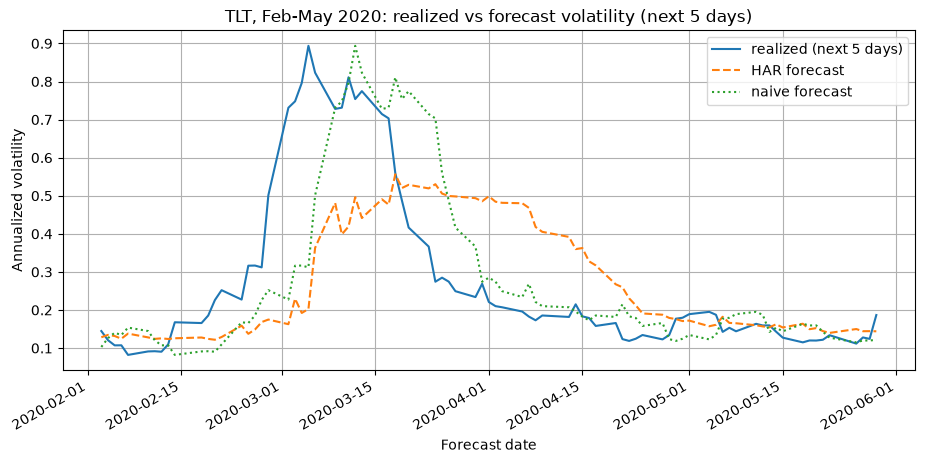

In [12]:
# Annualized volatility from 5-day variance: sqrt(variance * 252 / 5)
def to_ann_vol(var_5d: pd.Series) -> pd.Series:
    return np.sqrt(var_5d * 252 / HORIZON)

window = slice("2020-02", "2020-05")
tlt_2020 = pd.DataFrame({
    "realized (next 5 days)": to_ann_vol(y_te),
    "HAR forecast": to_ann_vol(tlt_har),
    "naive forecast": to_ann_vol(tlt_naive),
}).loc[window]

ax = tlt_2020.plot(
    figsize=(11, 5), grid=True, style=["-", "--", ":"],
    title="TLT, Feb-May 2020: realized vs forecast volatility (next 5 days)",
    xlabel="Forecast date", ylabel="Annualized volatility",
)
ax.figure.savefig("../figures/tlt_2020_forecasts.png", dpi=150, bbox_inches="tight")

# Key numbers: the peak of realized volatility and the forecasts made that day
peak = tlt_2020["realized (next 5 days)"].idxmax()
print(f"Peak realized vol: {tlt_2020.loc[peak, 'realized (next 5 days)']:.0%} "
      f"(5 days after {peak.date()})")
print(f"Forecasts made on {peak.date()}: HAR {tlt_2020.loc[peak, 'HAR forecast']:.0%}, "
      f"naive {tlt_2020.loc[peak, 'naive forecast']:.0%}")
print(f"Highest HAR forecast in the window: {tlt_2020['HAR forecast'].max():.0%}")

In March 2020 volatility in TLT went from about 15% to 89% over a two week period. On the 5th of March (just prior to the peak) HAR was forecasting 20% and the naive 31% so both were missing the onset of the spike. The naive forecast (which is just a copy of the last week) gets up to speed after one week. HAR is largely reliant on the monthly average so it stays well below the peak (at most 56%) and then it's too high in April when volatility comes back down. Those few weeks of large errors dominate the MSE and that's why HAR loses to the naive on MSE for TLT, despite being better in every other year.



## Conclusions
- QLIKE: HAR beats the naive forecast on QLIKE for all five assets. Its QLIKE is 0.64 (FXE) to 0.84 (TLT) times that of the naive.
- MSE. HAR beats naive on MSE for four assets (0.68 to 0.88 times naive), but not for TLT where its MSE is 1.25 times naive's. The per year check shows the loss comes from 2020: it's the only test year where HAR loses to naive on MSE (1.34) and without 2020 the ratio is 0.75. The chart above explains why. In March 2020 TLT's volatility went from around 15% to 89% in just two weeks. On March 5, just before the peak, HAR forecast 20% and naive 31%, so both missed the onset of the spike. The naive forecast simply copies the last week so it was able to catch up in one week. HAR is weighted mostly towards the monthly average (its slopes sum to about 3.5 which pulls it towards the 2007-2016 average) so it remained well below the peak (at most 56%) and then was still too high in April when the volatility came back down. The squaring of the errors means those few weeks dominate the total MSE. QLIKE on the other hand measures the errors relative to the volatility level so one extreme week is far less important and HAR still beats naive on QLIKE for TLT.
- FXE. HAR puts almost all its weight on the monthly term (beta_m = 4.02 versus 0.06 for daily and 0.14 for weekly). That's consistent with the daily variance estimates being so noisy that they're of little use on their own, so the benefit of averaging over 22 days is clear.
- SPY. The coefficients imply a long run daily variance of beta_0/(5-(beta_d+beta_w+beta_m)) = 0.000152/(5-4.16) which is about 21% annualized volatility.